In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys 
sys.path.append("..") 
from lens.raytrace import hit_z, refract_flat, crossing, exit_flat, trace_lens, cross_axis_back

In [2]:
def deriv(func, x, step = 1e-04):
    return (func(x + step) - func(x - step)) / (2 * step)

def gradient_descent(func, x0, lr, steps):
    loss = []
    for i in range(steps):
        x = x0 - lr * deriv(func, x0)
        loss.append(func(x))
        x0 = x
    return x, loss

def c(x):
    return (x - 1.5) ** 2 + 2

x, loss = gradient_descent(c, 0, 0.25, 30)
print(x)

1.4999999986026191


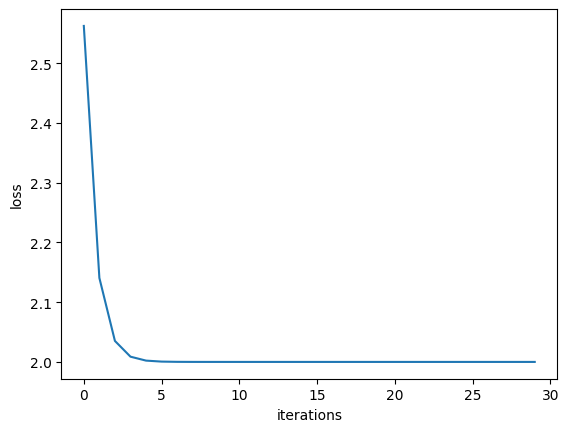

In [3]:
steps = 30
plt.plot(range(steps), loss)
plt.xlabel("iterations")
plt.ylabel("loss")
plt.show()

In [4]:
for lr in [0.05, 0.5, 0.95, 1.05]:
    x, loss = gradient_descent(c, 0, lr, 50)
    print(lr, "| first 4 losses:", np.round(loss[:4], 4), "| final x:", x)

0.05 | first 4 losses: [3.8225 3.4762 3.1957 2.9686] | final x: 1.492269337188934
0.5 | first 4 losses: [2. 2. 2. 2.] | final x: 1.4999999999998348
0.95 | first 4 losses: [3.8225 3.4762 3.1957 2.9686] | final x: 1.4922693371862694
1.05 | first 4 losses: [4.7225 5.2942 5.986  6.8231] | final x: -174.58627949127626


lr = 0.05: too slow. it creeps toward 1.5 and still isn’t there after 50 steps.

lr = 0.5: perfect. it lands exactly on 1.5 in one step and stays.

lr = 0.95: zigzag. it jumps back and forth across 1.5, slowly closing in.

lr = 1.05: explodes. every jump overshoots more than the last.

In [5]:
H = np.linspace(-10, 10, 1001)

def spot(z, R):
    y2, m2 = trace_lens(H, R, 1.5, 5)
    y = y2 + m2 * (z - 5)
    return np.sqrt(np.mean(y ** 2))

def spot_R25(z):
    return spot(z, 25)

z = 55
z25, loss = gradient_descent(spot_R25, z, 10, 30)
print(f"ends up at {z25}")

ends up at 50.22392207035313


In [6]:
print(f"spot size: {spot(z25, 25)}")

spot size: 0.0765259648450269


the spot size is exactly the same (except for negligible difference) as using a brute force approach!

In [7]:
def spot_at_50(R):
    return spot(50, R)

R = 30
R50, loss = gradient_descent(spot_at_50, R, 2, 60)
print(f"final R: {R50}")
print(f"spot size: {spot_at_50(R50)}")
print(f"spot size at R = 30: {spot_at_50(30)}")

final R: 24.905766938309974
spot size: 0.07717368456815106
spot size at R = 30: 1.042724278008005


it has been reduced by a LOT, which is the goal!!

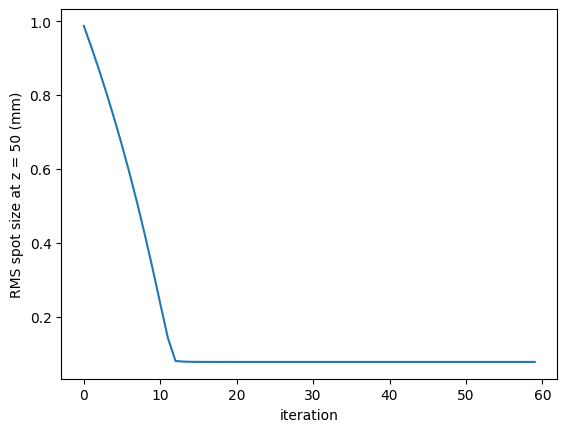

In [8]:
R50, loss5 = gradient_descent(spot_at_50, 30, 2, 60) 
plt.plot(range(60), loss5) 
plt.xlabel("iteration") 
plt.ylabel("RMS spot size at z = 50 (mm)") 
plt.show()

In [9]:
R1, loss1 = gradient_descent(spot_at_50, 30, 1, 60)
R2, loss2 = gradient_descent(spot_at_50, 30, 2, 60)
R3, loss3 = gradient_descent(spot_at_50, 30, 3, 60)

for name, L in [("lr = 1", loss1), ("lr = 2", loss2), ("lr = 3", loss3)]:
    below = [i + 1 for i in range(60) if L[i] < 0.08]
    first = below[0] if below else "never"
    print(name, "| first step below 0.08 mm:", first, "| last 3 losses:", np.round(L[-3:], 4))

lr = 1 | first step below 0.08 mm: 27 | last 3 losses: [0.0772 0.0772 0.0772]
lr = 2 | first step below 0.08 mm: 13 | last 3 losses: [0.0772 0.0772 0.0772]
lr = 3 | first step below 0.08 mm: never | last 3 losses: [0.0954 0.0936 0.0954]


lr = 2 gets below 0.08 mm fastest (13 steps). lr = 1 also gets there but takes twice as long (27). lr = 3 never settles: the bottom of the spot-vs-R curve is a sharp V, so a big step keeps jumping over it and bouncing between the two sides.

physically, the optimizer made the front surface more curved: R went from 30 to 24.91. a smaller R means a stronger lens with a closer focus. at R = 30 the lens focused too far, past the sensor, so the spot at z = 50 was 1.04 mm. the optimizer curved it until the lens’s best focus landed right on the sensor at 50.

the final spot (0.0772 mm) matches lesson 14’s best spot (0.077 mm) because at R = 25 the best focus was already 50.2, almost on the sensor, so only a tiny nudge was needed. it also shows 0.077 mm is about the floor for this lens: with one curved surface we can move the focus, but not remove the spherical aberration. getting sharper needs more knobs, like a second curved surface.